# FedEx Logistics Performance Analysis

**Goal:** assess delivery timeliness, operational bottlenecks, and logistics cost signals in the SCMS delivery history data. The dataset describes line-item records; unless explicitly aggregated, findings below are record-level and should not be read as unique-shipment counts.

### Questions
1. Does delivery mode relate to on-time performance?
2. Do country, managing team, or INCO terms show differences in delivery delay?
3. Is PO-to-vendor timing associated with delivery delay where a PO date exists?
4. Are shipment weight and line-item insurance cost associated?

**Method:** preserve raw fields, convert date and numeric fields with invalid/special text marked missing for calculations, document exclusions, and compare groups with sample sizes. Delays are actual delivery date minus scheduled date: positive = late; zero or negative = on-time. This is descriptive analysis, not proof of causation.

In [60]:
import io, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 70)
print('Libraries ready')

Libraries ready


## 1. Load the CSV

In [61]:
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/SCMS_Delivery_History_Dataset.csv'
df_raw = pd.read_csv(file_path, low_memory=False)
df = df_raw.copy()

print(f'Loaded {file_path}: {df.shape[0]:,} rows × {df.shape[1]} columns')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded /content/drive/MyDrive/SCMS_Delivery_History_Dataset.csv: 10,324 rows × 33 columns


## 2. First look and data dictionary

Check dimensions, sample records, types, summary statistics, and duplicate records before cleaning.

In [62]:
display(df.head())
display(df.tail())
print('Shape:', df.shape, '| Exact duplicate rows:', df.duplicated().sum())
df.info()
display(df.describe(include='all').T)

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Product Group,Sub Classification,Vendor,Item Description,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 Tests","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06,ARV,Pediatric,Aurobindo Pharma Limited,"Nevirapine 10mg/ml, oral suspension, Bottle, 240 ml",Nevirapine,Generic,10mg/ml,Oral suspension,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06,ARV,Adult,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LABORATORIES LIMITED),"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06,ARV,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Product Group,Sub Classification,Vendor,Item Description,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
10319,86818,103-ZW-T30,FPQ-15197,SO-50020,DN-4307,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,10/16/14,N/A - From RDC,31-Jul-15,15-Jul-15,20-Jul-15,ARV,Pediatric,SCMS from RDC,"Lamivudine/Nevirapine/Zidovudine 30/50/60mg, dispersible tablets, ...",Lamivudine/Nevirapine/Zidovudine,Generic,30/50/60mg,Chewable/dispersible tablet - FDC,60,166571,599655.60,3.60,0.06,"Mylan, H-12 & H-13, India",No,See DN-4307 (ID#:83920),See DN-4307 (ID#:83920),705.79
10320,86819,104-CI-T30,FPQ-15259,SO-50102,DN-4313,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,Truck,10/24/14,N/A - From RDC,31-Jul-15,6-Aug-15,7-Aug-15,ARV,Adult,SCMS from RDC,"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",Lamivudine/Zidovudine,Generic,150/300mg,Tablet - FDC,60,21072,137389.44,6.52,0.11,Hetero Unit III Hyderabad IN,No,See DN-4313 (ID#:83921),See DN-4313 (ID#:83921),161.71
10321,86821,110-ZM-T30,FPQ-14784,SO-49600,DN-4316,Zambia,PMO - US,From RDC,N/A - From RDC,Truck,8/12/14,N/A - From RDC,31-Aug-15,25-Aug-15,3-Sep-15,ARV,Adult,SCMS from RDC,"Efavirenz/Lamivudine/Tenofovir Disoproxil Fumarate 600/300/300mg, ...",Efavirenz/Lamivudine/Tenofovir Disoproxil Fumarate,Generic,600/300/300mg,Tablet - FDC,30,514526,5140114.74,9.99,0.33,Cipla Ltd A-42 MIDC Mahar. IN,No,Weight Captured Separately,Freight Included in Commodity Cost,5284.04
10322,86822,200-ZW-T30,FPQ-16523,SO-51680,DN-4334,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,7/1/15,N/A - From RDC,9-Sep-15,4-Aug-15,11-Aug-15,ARV,Adult,SCMS from RDC,"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",Lamivudine/Zidovudine,Generic,150/300mg,Tablet - FDC,60,17465,113871.80,6.52,0.11,Mylan (formerly Matrix) Nashik,Yes,1392,Freight Included in Commodity Cost,134.03
10323,86823,103-ZW-T30,FPQ-15197,SO-50022,DN-4336,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,10/16/14,N/A - From RDC,31-Aug-15,4-Aug-15,11-Aug-15,ARV,Pediatric,SCMS from RDC,"Lamivudine/Zidovudine 30/60mg, dispersible tablets, 60 Tabs",Lamivudine/Zidovudine,Generic,30/60mg,Chewable/dispersible tablet - FDC,60,36639,72911.61,1.99,0.03,"Cipla, Goa, India",No,Weight Captured Separately,Freight Included in Commodity Cost,85.82


Shape: (10324, 33) | Exact duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  object 
 2   PQ #                          10324 non-null  object 
 3   PO / SO #                     10324 non-null  object 
 4   ASN/DN #                      10324 non-null  object 
 5   Country                       10324 non-null  object 
 6   Managed By                    10324 non-null  object 
 7   Fulfill Via                   10324 non-null  object 
 8   Vendor INCO Term              10324 non-null  object 
 9   Shipment Mode                 9964 non-null   object 
 10  PQ First Sent to Client Date  10324 non-null  object 
 11  PO Sent to Vendor Date        10324 non-null  object 
 12  Scheduled Deliv

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,10324.0,NaN,NaN,NaN,51098.968229,31944.332496,1.0,12795.75,57540.5,83648.25,86823.0
Project Code,10324,142,116-ZA-T30,768,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PQ #,10324,1237,Pre-PQ Process,2681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PO / SO #,10324,6233,SCMS-199289,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ASN/DN #,10324,7030,ASN-19166,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,10324,43,South Africa,1406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Managed By,10324,4,PMO - US,10265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fulfill Via,10324,2,From RDC,5404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vendor INCO Term,10324,8,N/A - From RDC,5404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Shipment Mode,9964,4,Air,6113,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [63]:
data_dictionary = pd.DataFrame({
 'Column': df.columns,
 'Non-null': df.notna().sum().values,
 'Missing': df.isna().sum().values,
 'Unique': df.nunique(dropna=True).values,
 'Data type': df.dtypes.astype(str).values
})
display(data_dictionary)

,Column,Non-null,Missing,Unique,Data type
0,ID,10324,0,10324,int64
1,Project Code,10324,0,142,object
2,PQ #,10324,0,1237,object
3,PO / SO #,10324,0,6233,object
4,ASN/DN #,10324,0,7030,object
5,Country,10324,0,43,object
6,Managed By,10324,0,4,object
7,Fulfill Via,10324,0,2,object
8,Vendor INCO Term,10324,0,8,object
9,Shipment Mode,9964,360,4,object


### Field meanings

| Field | Meaning |
|---|---|
| ID | Unique logistics record identifier |
| Project Code | Project or initiative tied to the shipment |
| PQ # | Price quotation reference or process marker |
| PO / SO # | Purchase or sales order reference |
| ASN/DN # | Advance shipment notice or delivery note reference |
| Country | Destination country |
| Managed By | Team responsible for the project |
| Fulfill Via | Fulfillment path, such as direct drop or distribution center |
| Vendor INCO Term | Vendor delivery agreement term |
| Shipment Mode | Transport mode (air, truck, air charter, ocean) |
| PQ First Sent to Client Date | Date quotation was first sent to client |
| PO Sent to Vendor Date | Date purchase order was sent to vendor |
| Scheduled Delivery Date | Planned delivery date |
| Delivered to Client Date | Actual delivery date |
| Delivery Recorded Date | Date delivery was entered in the system |
| Product Group | Broad product category |
| Sub Classification | Product subgroup |
| Vendor | Supplier name |
| Item Description | Detailed shipped-item description |
| Molecule/Test Type | Pharmaceutical molecule or test type |
| Brand | Product brand |
| Dosage | Dose strength where applicable |
| Dosage Form | Product form, such as tablet or test kit |
| Unit of Measure (Per Pack) | Units contained in each pack |
| Line Item Quantity | Number of units/packs recorded for the line item |
| Line Item Value | Total value of the line item |
| Pack Price | Price per pack |
| Unit Price | Price per individual unit |
| Manufacturing Site | Product manufacturing location |
| First Line Designation | Whether product is designated for first-line use |
| Weight (Kilograms) | Recorded shipment/line-item weight in kilograms |
| Freight Cost (USD) | Freight cost recorded in US dollars |
| Line Item Insurance (USD) | Insurance cost recorded for the line item |

Some fields contain process labels or explanatory text instead of dates/numbers; those values remain in the raw data and are excluded from calculations requiring valid dates or numbers.

## 3. Clean and prepare analysis fields

The source includes text markers such as “Date Not Captured”, “N/A - From RDC”, “Weight Captured Separately”, and freight notes. These are retained in the raw table and become missing only in derived numeric/date analysis fields. We do not impute unknown dates, weight, freight, or insurance.

In [64]:
date_cols = ['PQ First Sent to Client Date','PO Sent to Vendor Date','Scheduled Delivery Date','Delivered to Client Date','Delivery Recorded Date']
for c in date_cols:
    # mixed date formats occur in the source; placeholders safely become NaT
    df[c + ' Parsed'] = pd.to_datetime(df[c], format='mixed', errors='coerce')

numeric_cols = ['Unit of Measure (Per Pack)','Line Item Quantity','Line Item Value','Pack Price','Unit Price','Weight (Kilograms)','Freight Cost (USD)','Line Item Insurance (USD)']
for c in numeric_cols:
    if c == 'Unit of Measure (Per Pack)' or c in ['Line Item Quantity','Line Item Value','Pack Price','Unit Price','Line Item Insurance (USD)']:
        df[c + ' Numeric'] = pd.to_numeric(df[c].astype(str).str.replace(',','',regex=False).str.replace('$','',regex=False).str.strip(), errors='coerce')
    else:
        cleaned = df[c].astype(str).str.replace(',','',regex=False).str.replace('$','',regex=False).str.strip()
        df[c + ' Numeric'] = pd.to_numeric(cleaned, errors='coerce')

df['Delivery Delay Days'] = (df['Delivered to Client Date Parsed'] - df['Scheduled Delivery Date Parsed']).dt.days
df['On Time'] = df['Delivery Delay Days'].le(0)
df['Delivery Status'] = np.select([df['Delivery Delay Days'].isna(), df['Delivery Delay Days'] > 0], ['Unknown date','Late'], default='On time / early')
df['PO-to-Scheduled Lead Days'] = (df['Scheduled Delivery Date Parsed'] - df['PO Sent to Vendor Date Parsed']).dt.days
print('Unparseable / missing derived values:')
display(pd.DataFrame({'Missing after parse':df[[c+' Parsed' for c in date_cols]+[c+' Numeric' for c in numeric_cols]].isna().sum()}))
print('Delivery status:')
display(df['Delivery Status'].value_counts(dropna=False).to_frame('Records'))

Unparseable / missing derived values:


,Missing after parse
PQ First Sent to Client Date Parsed,2681
PO Sent to Vendor Date Parsed,5732
Scheduled Delivery Date Parsed,0
Delivered to Client Date Parsed,0
Delivery Recorded Date Parsed,0
Unit of Measure (Per Pack) Numeric,0
Line Item Quantity Numeric,0
Line Item Value Numeric,0
Pack Price Numeric,0
Unit Price Numeric,0


Delivery status:


,Records
Delivery Status,
On time / early,9138
Late,1186


## 4. Missing values and unusual values

Missing values are reported before decisions. Special text markers are not treated as zero. Outliers are inspected using distributions and IQR fences; valid extremes are retained unless source evidence shows an error, since unusually large shipments can be operationally real.

In [65]:
missing = pd.DataFrame({'Missing':df_raw.isna().sum(), 'Missing %':(df_raw.isna().mean()*100).round(2)})
display(missing[missing['Missing']>0].sort_values('Missing',ascending=False))
for c in ['Delivery Delay Days','Weight (Kilograms) Numeric','Freight Cost (USD) Numeric','Line Item Insurance (USD) Numeric']:
    x=df[c].dropna()
    if len(x):
        q1,q3=x.quantile([.25,.75]); iqr=q3-q1
        print(f'{c}: n={len(x):,}, median={x.median():,.2f}, IQR=[{q1:,.2f}, {q3:,.2f}], IQR-fence count={((x<q1-1.5*iqr)|(x>q3+1.5*iqr)).sum():,}')

,Missing,Missing %
Dosage,1736,16.82
Shipment Mode,360,3.49
Line Item Insurance (USD),287,2.78


Delivery Delay Days: n=10,324, median=0.00, IQR=[-3.00, 0.00], IQR-fence count=3,127
Weight (Kilograms) Numeric: n=6,372, median=1,047.00, IQR=[206.75, 3,334.00], IQR-fence count=623
Freight Cost (USD) Numeric: n=6,198, median=5,869.66, IQR=[2,131.12, 14,406.57], IQR-fence count=388
Line Item Insurance (USD) Numeric: n=10,037, median=47.04, IQR=[6.51, 252.40], IQR-fence count=1,116


## 5. Delivery performance overview

In [66]:
valid = df.dropna(subset=['Delivery Delay Days']).copy()
summary = pd.Series({
 'Records with usable scheduled and delivered dates':len(valid),
 'Late records':int((valid['Delivery Delay Days']>0).sum()),
 'On-time / early records':int((valid['Delivery Delay Days']<=0).sum()),
 'Late rate (%)':round((valid['Delivery Delay Days']>0).mean()*100,2),
 'On-time / early rate (%)':round((valid['Delivery Delay Days']<=0).mean()*100,2),
 'Median delay (days)':round(valid['Delivery Delay Days'].median(),2),
 'Mean delay (days)':round(valid['Delivery Delay Days'].mean(),2)
})
display(summary.to_frame('Value'))
print('Interpretation: the late rate uses only records with both scheduled and delivered dates; early/on-time is delay <= 0.')

,Value
Records with usable scheduled and delivered dates,10324.00
Late records,1186.00
On-time / early records,9138.00
Late rate (%),11.49
On-time / early rate (%),88.51
Median delay (days),0.00
Mean delay (days),-6.02


Interpretation: the late rate uses only records with both scheduled and delivered dates; early/on-time is delay <= 0.


## 6. Visual exploration (at least five chart types)

### Chart 1 — Histogram: delivery delay distribution

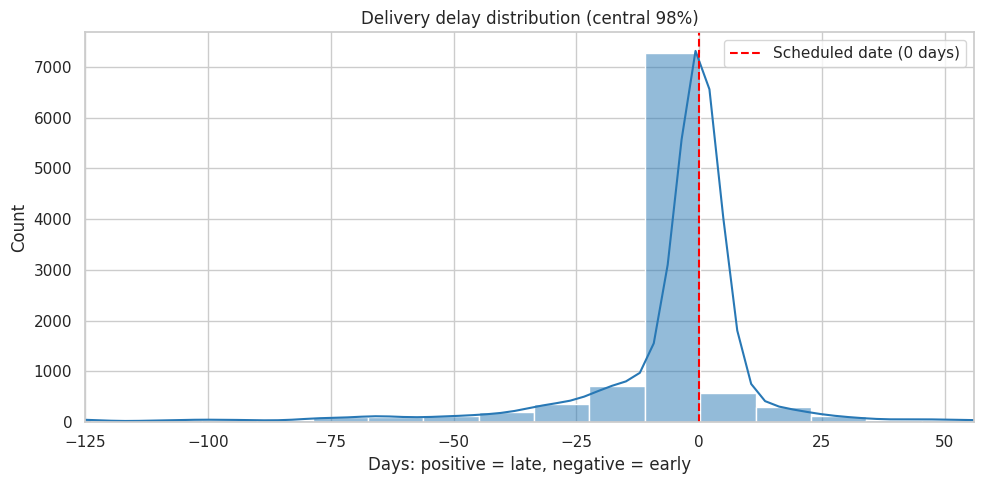

In [67]:
plt.figure(figsize=(10,5))
sns.histplot(valid['Delivery Delay Days'], bins=50, kde=True, color='#2878B5')
plt.axvline(0,color='red',linestyle='--',label='Scheduled date (0 days)')
plt.xlim(valid['Delivery Delay Days'].quantile(.01),valid['Delivery Delay Days'].quantile(.99))
plt.title('Delivery delay distribution (central 98%)'); plt.xlabel('Days: positive = late, negative = early'); plt.legend(); plt.tight_layout(); plt.show()

### Chart 2 — Bar chart: on-time rate by shipment mode

Small groups are shown with sample sizes; missing mode remains visible.

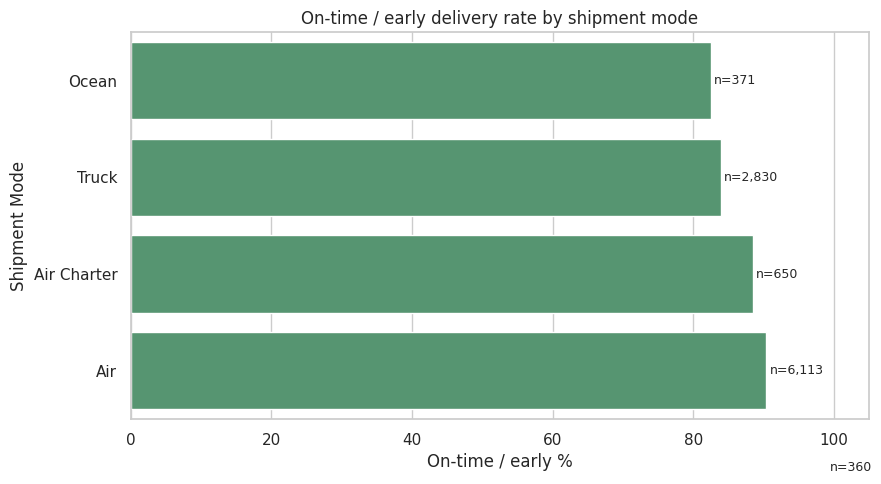

,Shipment Mode,records,On-time / early %,median_delay
2,Ocean,371,82.479784,0.0
3,Truck,2830,83.922261,0.0
1,Air Charter,650,88.461538,-13.0
0,Air,6113,90.397513,0.0
4,NaN,360,98.888889,0.0


In [68]:
mode = df.dropna(subset=['Delivery Delay Days']).groupby('Shipment Mode',dropna=False).agg(records=('On Time','size'), on_time_rate=('On Time','mean'), median_delay=('Delivery Delay Days','median')).reset_index()
mode['On-time / early %']=mode['on_time_rate']*100
mode=mode[mode.records>=30].sort_values('On-time / early %')
plt.figure(figsize=(9,5)); sns.barplot(data=mode,x='On-time / early %',y='Shipment Mode',color='#4C9F70')
for i,(_,r) in enumerate(mode.iterrows()): plt.text(r['On-time / early %']+0.5,i,f"n={int(r['records']):,}",va='center',fontsize=9)
plt.xlim(0,105); plt.title('On-time / early delivery rate by shipment mode'); plt.tight_layout(); plt.show(); display(mode[['Shipment Mode','records','On-time / early %','median_delay']])

### Chart 3 — Box plot: delay by shipment mode

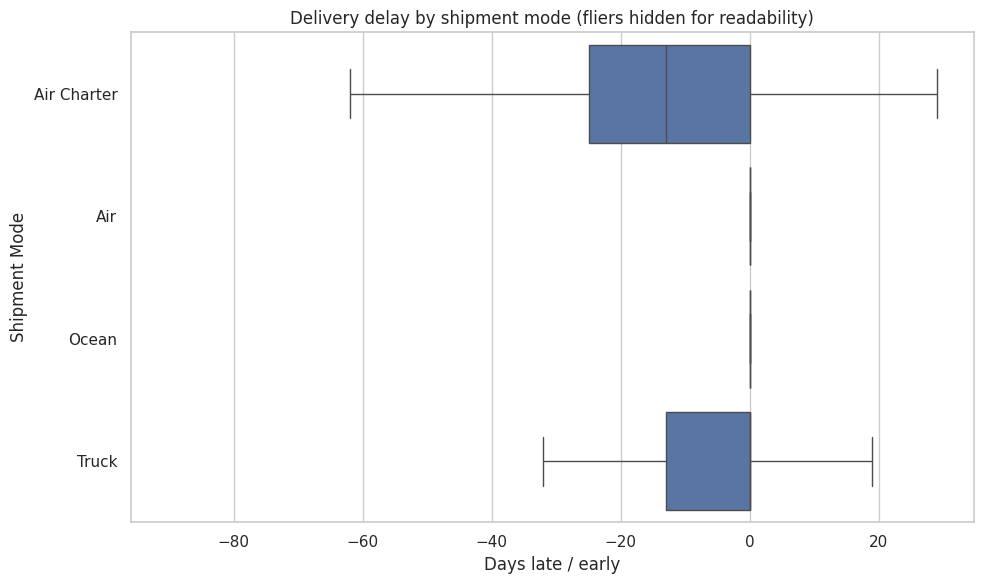

In [69]:
plotdf=valid[valid['Shipment Mode'].notna()].copy()
order=plotdf.groupby('Shipment Mode')['Delivery Delay Days'].median().sort_values().index
plt.figure(figsize=(10,6)); sns.boxplot(data=plotdf,x='Delivery Delay Days',y='Shipment Mode',order=order,showfliers=False)
plt.xlim(plotdf['Delivery Delay Days'].quantile(.02),plotdf['Delivery Delay Days'].quantile(.98))
plt.title('Delivery delay by shipment mode (fliers hidden for readability)'); plt.xlabel('Days late / early'); plt.tight_layout(); plt.show()

### Chart 4 — Country comparison

Only countries with at least 30 date-valid records are compared to reduce unstable rates.

In [70]:
country=valid.groupby('Country').agg(records=('On Time','size'),on_time_rate=('On Time','mean'),median_delay=('Delivery Delay Days','median')).query('records >= 30').sort_values('on_time_rate').tail(20).reset_index()
country['On-time / early %']=country.on_time_rate*100
fig=px.bar(country.sort_values('On-time / early %'),x='On-time / early %',y='Country',orientation='h',color='median_delay',color_continuous_scale='RdYlGn_r',hover_data=['records','median_delay'],title='On-time / early rate by country (minimum 30 records)')
fig.show()

### Chart 5 — Scatter plot: weight and insurance

This compares line-item values where both fields are numeric. Correlation is descriptive and can be influenced by product type, value, and shipment structure.

In [71]:
wi=df.dropna(subset=['Weight (Kilograms) Numeric','Line Item Insurance (USD) Numeric']).copy()
wi=wi[(wi['Weight (Kilograms) Numeric']>0)&(wi['Line Item Insurance (USD) Numeric']>=0)]
print('Usable weight-insurance records:',len(wi))
if len(wi)>=3:
    print('Spearman correlation:',round(wi['Weight (Kilograms) Numeric'].corr(wi['Line Item Insurance (USD) Numeric'],method='spearman'),3))
    fig=px.scatter(wi,x='Weight (Kilograms) Numeric',y='Line Item Insurance (USD) Numeric',opacity=.45,trendline='ols',title='Weight vs line-item insurance (central 99% shown)',labels={'Weight (Kilograms) Numeric':'Weight (kg)','Line Item Insurance (USD) Numeric':'Insurance (USD)'})
    fig.update_xaxes(range=[0,wi['Weight (Kilograms) Numeric'].quantile(.99)]); fig.update_yaxes(range=[0,wi['Line Item Insurance (USD) Numeric'].quantile(.99)]); fig.show()

Usable weight-insurance records: 6176
Spearman correlation: 0.779


### Chart 6 — Correlation heatmap

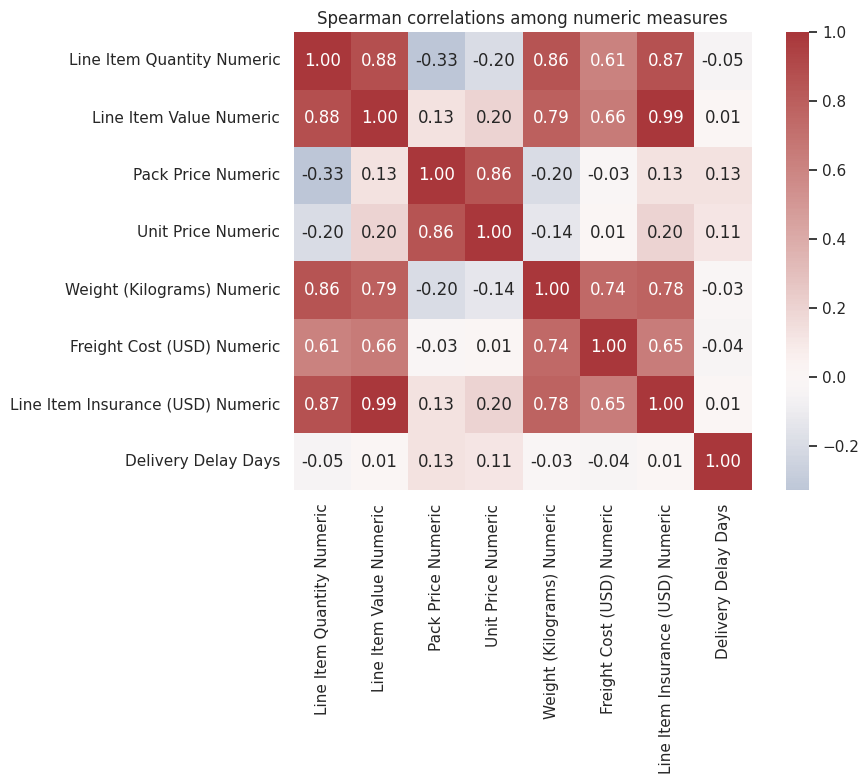

In [72]:
corr_cols=['Line Item Quantity Numeric','Line Item Value Numeric','Pack Price Numeric','Unit Price Numeric','Weight (Kilograms) Numeric','Freight Cost (USD) Numeric','Line Item Insurance (USD) Numeric','Delivery Delay Days']
corr=df[corr_cols].corr(method='spearman',numeric_only=True)
plt.figure(figsize=(10,8)); sns.heatmap(corr,annot=True,fmt='.2f',cmap='vlag',center=0,square=True)
plt.title('Spearman correlations among numeric measures'); plt.tight_layout(); plt.show()

### Chart 7 — Monthly line chart: median delay over time

In [73]:
monthly=valid.dropna(subset=['Delivered to Client Date Parsed']).copy()
monthly['Delivery Month']=monthly['Delivered to Client Date Parsed'].dt.to_period('M').dt.to_timestamp()
monthly=monthly.groupby('Delivery Month').agg(records=('Delivery Delay Days','size'),median_delay=('Delivery Delay Days','median')).reset_index()
fig=px.line(monthly,x='Delivery Month',y='median_delay',hover_data=['records'],markers=True,title='Monthly median delivery delay',labels={'median_delay':'Median delay (days)'})
fig.add_hline(y=0,line_dash='dash',line_color='red'); fig.show()

### Chart 8 — INCO term performance (interactive)

INCO terms are compared as recorded. “N/A - From RDC” is a fulfillment category and may not be directly comparable to negotiated vendor terms.

In [74]:
incoterm=valid.groupby('Vendor INCO Term').agg(records=('On Time','size'),on_time_rate=('On Time','mean'),median_delay=('Delivery Delay Days','median')).reset_index()
incoterm['On-time / early %']=incoterm.on_time_rate*100
incoterm=incoterm[incoterm.records>=30]
fig=px.bar(incoterm.sort_values('On-time / early %'),x='Vendor INCO Term',y='On-time / early %',color='median_delay',hover_data=['records','median_delay'],title='Delivery performance by INCO term (minimum 30 records)')
fig.show(); display(incoterm.sort_values('on_time_rate'))

,Vendor INCO Term,records,on_time_rate,median_delay,On-time / early %
7,N/A - From RDC,5404,0.828460,0.0,82.846040
3,DDP,1443,0.919612,0.0,91.961192
5,EXW,2778,0.950324,0.0,95.032397
6,FCA,397,0.989924,0.0,98.992443
1,CIP,275,0.996364,0.0,99.636364


## 7. Project milestone analyses

### PO-to-scheduled lead time vs delivery delay

The “N/A - From RDC” and uncaptured PO dates cannot provide a PO-to-scheduled interval; those records are excluded only from this question.

In [75]:
lead=df.dropna(subset=['PO-to-Scheduled Lead Days','Delivery Delay Days']).copy()
lead=lead[(lead['PO-to-Scheduled Lead Days']>=0)&(lead['PO-to-Scheduled Lead Days']<=3650)]
print('Records with usable non-negative lead time:',len(lead))
if len(lead)>=3:
    print('Spearman correlation with delay:',round(lead['PO-to-Scheduled Lead Days'].corr(lead['Delivery Delay Days'],method='spearman'),3))
    lead['Lead-time band']=pd.cut(lead['PO-to-Scheduled Lead Days'],bins=[-1,30,60,90,180,365,3650],labels=['0–30','31–60','61–90','91–180','181–365','>365'])
    lead_summary=lead.groupby('Lead-time band',observed=True).agg(records=('On Time','size'),late_rate=('Delivery Delay Days',lambda x:(x>0).mean()*100),median_delay=('Delivery Delay Days','median')).reset_index()
    display(lead_summary)
    fig=px.bar(lead_summary,x='Lead-time band',y='late_rate',hover_data=['records','median_delay'],title='Late rate by PO-to-scheduled lead-time band',labels={'late_rate':'Late records (%)'})
    fig.show()

Records with usable non-negative lead time: 4588
Spearman correlation with delay: 0.041


,Lead-time band,records,late_rate,median_delay
0,0–30,648,2.469136,0.0
1,31–60,695,3.741007,0.0
2,61–90,896,8.370536,0.0
3,91–180,1719,5.759162,0.0
4,181–365,600,6.500000,0.0
5,>365,30,0.000000,0.0


## 8. Findings and stakeholder actions

The following summary is generated from the loaded file; verify group sample sizes before acting. Treat differences as signals for further investigation, not causal effects.

In [76]:
late_rate=(valid['Delivery Delay Days']>0).mean()*100 if len(valid) else np.nan
mode_action=mode.sort_values('On-time / early %') if 'mode' in globals() else pd.DataFrame()
country_action=valid.groupby('Country').agg(records=('On Time','size'),on_time=('On Time','mean'),median_delay=('Delivery Delay Days','median')).query('records >= 30').sort_values('on_time')
ins_corr=wi['Weight (Kilograms) Numeric'].corr(wi['Line Item Insurance (USD) Numeric'],method='spearman') if len(wi)>=3 else np.nan
print(f'Overall late rate among {len(valid):,} date-valid records: {late_rate:.1f}%')
if len(mode_action):
    print('Shipment mode lowest on-time/early rate (n>=30):',mode_action.iloc[0]['Shipment Mode'],f"({mode_action.iloc[0]['On-time / early %']:.1f}%, n={int(mode_action.iloc[0]['records']):,})")
if len(country_action):
    print('Lowest on-time/early country among groups with n>=30:',country_action.index[0],f"({country_action.iloc[0]['on_time']*100:.1f}%, n={int(country_action.iloc[0]['records']):,})")
print('Weight-insurance Spearman correlation:',round(ins_corr,3) if pd.notna(ins_corr) else 'not enough usable data')
print('Recommended follow-up: review recurring late lanes/modes with operations; validate vendor, country and schedule planning factors; investigate weight-insurance pricing with product/value controls before changing rates.')

Overall late rate among 10,324 date-valid records: 11.5%
Shipment mode lowest on-time/early rate (n>=30): Ocean (82.5%, n=371)
Lowest on-time/early country among groups with n>=30: Burundi (61.2%, n=98)
Weight-insurance Spearman correlation: 0.779
Recommended follow-up: review recurring late lanes/modes with operations; validate vendor, country and schedule planning factors; investigate weight-insurance pricing with product/value controls before changing rates.


## 9. Limitations and next steps

- Records are line items; one shipment may appear in multiple rows. Shipment-level results require a validated shipment key and aggregation rule.
- Date validity and completeness affect every delivery metric. Unknown delivery dates are excluded, not assumed on-time.
- Country, team, mode, and INCO term are observational attributes; results do not establish that a factor caused delay.
- Weight, freight, and insurance include non-numeric source notes. Cost comparisons use only numeric entries and may have selection bias.
- Managing team is highly imbalanced in the source; avoid ranking teams with tiny sample sizes.
- Next: validate outlying records with source owners; compare modes on matched routes/product groups; model delay with route, time, vendor, and product controls; quantify cost per unit and freight share after confirming units and shipment aggregation.